Hypothese 1: Das Modell mit der höchsten Accuracy bei wenigen Trainingsdaten muss nach mehreren Traingsrunden bei mehr Trainingsdaten nicht das beste sein

In [13]:
import matplotlib.pyplot as plt
from sklearn.datasets import make_moons
from sklearn.ensemble import RandomForestClassifier
from sklearn.linear_model import LogisticRegression
from sklearn.model_selection import train_test_split
from sklearn.neural_network import MLPClassifier
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import StandardScaler
from sklearn.tree import DecisionTreeClassifier

from probly.evaluation.active_learning import (
    MarginSampling,
    active_learning_steps,
    from_dataset,
)

SEED = 42

X, y = make_moons(n_samples=600, noise=0.25, random_state=SEED)

X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.3, random_state=SEED, stratify=y)

models = {
    "Logistic Regression": make_pipeline(StandardScaler(), LogisticRegression(random_state=SEED)),
    "Random Forest": RandomForestClassifier(n_estimators=100, random_state=SEED),
    "Neural Network": make_pipeline(
        StandardScaler(), MLPClassifier(hidden_layer_sizes=(20, 20), max_iter=500, random_state=SEED)
    ),
    "Decision Tree": DecisionTreeClassifier(max_depth=5, random_state=SEED),
}

Active Learning:

In [ ]:
from sklearn.base import clone
from sklearn.metrics import accuracy_score

results = {}

for name, model in models.items():
    pool = from_dataset(X_train, y_train, X_test, y_test, initial_size=30, seed=SEED)

    strategy = MarginSampling()

    sizes = []
    accuracies = []

    for state in active_learning_steps(pool, clone(model), strategy, query_size=20, n_iterations=100):
        predictions = state.estimator.predict(state.pool.x_test)

        accuracy = accuracy_score(state.pool.y_test, predictions)

        sizes.append(state.pool.n_labeled)
        accuracies.append(accuracy)

    results[name] = (sizes, accuracies)

/home/mira/probly/.venv/lib/python3.13/site-packages/sklearn/neural_network/_multilayer_perceptron.py:785: ConvergenceWarning: Stochastic Optimizer: Maximum iterations (500) reached and the optimization hasn't converged yet.
  warnings.warn(
/home/mira/probly/.venv/lib/python3.13/site-packages/sklearn/neural_network/_multilayer_perceptron.py:785: ConvergenceWarning: Stochastic Optimizer: Maximum iterations (500) reached and the optimization hasn't converged yet.
  warnings.warn(
/home/mira/probly/.venv/lib/python3.13/site-packages/sklearn/neural_network/_multilayer_perceptron.py:785: ConvergenceWarning: Stochastic Optimizer: Maximum iterations (500) reached and the optimization hasn't converged yet.
  warnings.warn(
/home/mira/probly/.venv/lib/python3.13/site-packages/sklearn/neural_network/_multilayer_perceptron.py:785: ConvergenceWarning: Stochastic Optimizer: Maximum iterations (500) reached and the optimization hasn't converged yet.
  warnings.warn(


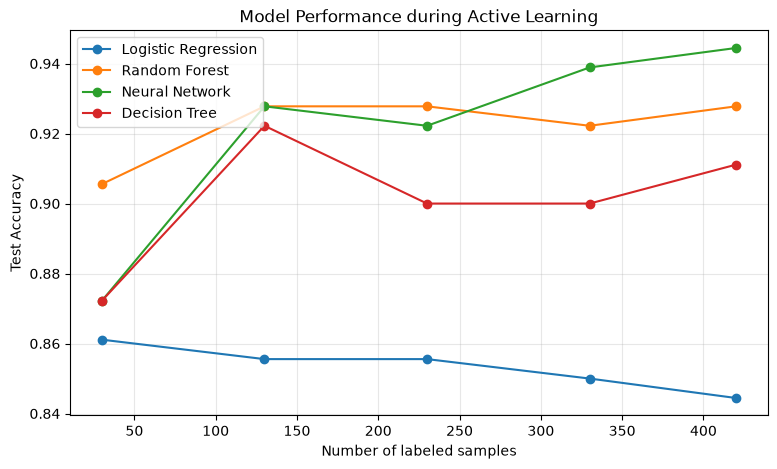

In [15]:
plt.figure(figsize=(9, 5))

for name, (sizes, accuracies) in results.items():
    plt.plot(sizes, accuracies, marker="o", label=name)

plt.xlabel("Number of labeled samples")
plt.ylabel("Test Accuracy")
plt.title("Model Performance during Active Learning")
plt.legend()
plt.grid(alpha=0.3)
plt.show()